In [3]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, Input
from sklearn.metrics import confusion_matrix, classification_report

In [4]:
from PIL import Image

def clean_bad_images(folder_path):
    removed = 0
    for class_name in ["Cat", "Dog"]:
        class_dir = os.path.join(folder_path, class_name)
        for filename in os.listdir(class_dir):
            file_path = os.path.join(class_dir, filename)
            try:
                with Image.open(file_path) as img:
                    if img.mode not in ('L', 'RGB', 'RGBA'):
                        print(f"Removing bad image: {file_path} (mode: {img.mode})")
                        os.remove(file_path)
                        removed += 1
            except Exception as e:
                print(f"Removing corrupted image: {file_path} (Error: {e})")
                os.remove(file_path)
                removed += 1
    print(f"Done! Removed {removed} bad images.")

clean_bad_images("data_split/train")
clean_bad_images("data_split/val")
clean_bad_images("data_split/test")

Removing bad image: data_split/train\Dog\5604.jpg (mode: P)
Removing corrupted image: data_split/train\Dog\5604.jpg (Error: [WinError 32] The process cannot access the file because it is being used by another process: 'data_split/train\\Dog\\5604.jpg')
Removing bad image: data_split/train\Dog\6059.jpg (mode: P)
Removing corrupted image: data_split/train\Dog\6059.jpg (Error: [WinError 32] The process cannot access the file because it is being used by another process: 'data_split/train\\Dog\\6059.jpg')
Removing bad image: data_split/train\Dog\6245.jpg (mode: CMYK)
Removing corrupted image: data_split/train\Dog\6245.jpg (Error: [WinError 32] The process cannot access the file because it is being used by another process: 'data_split/train\\Dog\\6245.jpg')
Removing bad image: data_split/train\Dog\6318.jpg (mode: P)
Removing corrupted image: data_split/train\Dog\6318.jpg (Error: [WinError 32] The process cannot access the file because it is being used by another process: 'data_split/train\\D

c:\Users\aahan\AppData\Local\Programs\Python\Python311\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Removing bad image: data_split/train\Dog\9188.jpg (mode: P)
Removing corrupted image: data_split/train\Dog\9188.jpg (Error: [WinError 32] The process cannot access the file because it is being used by another process: 'data_split/train\\Dog\\9188.jpg')
Done! Removed 11 bad images.
Removing bad image: data_split/val\Cat\11935.jpg (mode: P)
Removing corrupted image: data_split/val\Cat\11935.jpg (Error: [WinError 32] The process cannot access the file because it is being used by another process: 'data_split/val\\Cat\\11935.jpg')
Removing bad image: data_split/val\Cat\2663.jpg (mode: P)
Removing corrupted image: data_split/val\Cat\2663.jpg (Error: [WinError 32] The process cannot access the file because it is being used by another process: 'data_split/val\\Cat\\2663.jpg')
Removing bad image: data_split/val\Dog\6718.jpg (mode: P)
Removing corrupted image: data_split/val\Dog\6718.jpg (Error: [WinError 32] The process cannot access the file because it is being used by another process: 'data_s

In [5]:
import os,random,shutil
import tensorflow as tf
SEED = 42
random.seed(SEED)

In [6]:
def split_dataset(src_dir, out_dir, classes, ratios=(0.8, 0.1, 0.1)):
    random.seed(SEED)  
    for cls in classes:
        src = os.path.join(src_dir, cls)
        files = os.listdir(src)
        random.shuffle(files)         

        n = len(files)
        n_train = int(n * ratios[0])
        n_val   = int(n * ratios[1])

        splits = {
            "train": files[:n_train],
            "val":   files[n_train : n_train + n_val],
            "test":  files[n_train + n_val :],
        }

        for split_name, split_files in splits.items():
            dst = os.path.join(out_dir, split_name, cls)
            os.makedirs(dst, exist_ok=True)   
            for f in split_files:
                shutil.copy(os.path.join(src, f), os.path.join(dst, f))

        print(f"{cls}: train={len(splits['train'])}, "
              f"val={len(splits['val'])}, test={len(splits['test'])}")

In [7]:
split_dataset(
    src_dir="PetImages",
    out_dir="data_split",
    classes=["Cat", "Dog"],
)

Cat: train=9999, val=1249, test=1251
Dog: train=9999, val=1249, test=1251


In [8]:
for split in ["train", "val", "test"]:
    for cls in ["Cat", "Dog"]:
        p = os.path.join("data_split", split, cls)
        n = len(os.listdir(p))
        print(f"{split:5s} {cls}: {n}")

train Cat: 9999
train Dog: 9999
val   Cat: 1249
val   Dog: 1249
test  Cat: 1251
test  Dog: 1251


In [9]:
def names(folder):
    return set(os.listdir(folder))

cat_train = names("data_split/train/Cat")
cat_val   = names("data_split/val/Cat")
cat_test  = names("data_split/test/Cat")

print("cat overlap train∩val:", cat_train & cat_val)
print("cat overlap train∩test:", cat_train & cat_test)
print("cat overlap val∩test:", cat_val & cat_test)

cat overlap train∩val: set()
cat overlap train∩test: set()
cat overlap val∩test: set()


In [10]:
IMG_SIZE = (180,180)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

In [23]:
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    "data_split/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "data_split/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "data_split/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,
)

normalization_layer = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y)).prefetch(AUTOTUNE)
val_ds   = val_ds.map(lambda x, y: (normalization_layer(x), y)).prefetch(AUTOTUNE)
test_ds  = test_ds.map(lambda x, y: (normalization_layer(x), y)).prefetch(AUTOTUNE)

medium_train_ds = train_ds.take(300)
medium_val_ds = val_ds

Found 19998 files belonging to 2 classes.
Found 2498 files belonging to 2 classes.
Found 2502 files belonging to 2 classes.


In [13]:
for images, labels in train_ds.take(1):
    print("images shape:", images.shape)
    print("labels shape:", labels.shape)
    print("image dtype :", images.dtype)
    print("pixel min/max:", images.numpy().min(), images.numpy().max())
    print("label values:", labels.numpy().ravel()[:8])

images shape: (32, 180, 180, 3)
labels shape: (32, 1)
image dtype : <dtype: 'float32'>
pixel min/max: 0.0 255.0
label values: [0. 1. 0. 1. 1. 0. 0. 0.]


In [24]:
normalization_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds   = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds  = test_ds.map(lambda x, y: (normalization_layer(x), y))

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

In [15]:
for images, labels in train_ds.take(1):
    print("pixel min/max after normalize:", images.numpy().min(), images.numpy().max())

pixel min/max after normalize: 0.0 1.0


In [ ]:
# ── Block M1: Input ───────────────────────────────────────────
inputs = Input(shape=(180, 180, 3))

# ── Block M2: Conv + Pool (edges) ────────────────────────────
x = layers.Conv2D(32, (3, 3), activation="relu")(inputs)
x = layers.MaxPooling2D((2, 2))(x)

# ── Block M3: Conv + Pool (textures) ─────────────────────────
x = layers.Conv2D(64, (3, 3), activation="relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

# ── Block M4: Conv + Pool (parts) ────────────────────────────
x = layers.Conv2D(128, (3, 3), activation="relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

# ── Block M5: Flatten ────────────────────────────────────────
x = layers.Flatten()(x)

# ── Block M6: Dense hidden ───────────────────────────────────
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)

# ── Block M7: Output ─────────────────────────────────────────
outputs = layers.Dense(1, activation="sigmoid")(x)

# ── Block M8: Build + summary ────────────────────────────────
model = models.Model(inputs=inputs, outputs=outputs)
model.summary()

# ── Block M9: Compile ────────────────────────────────────────
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

# ── Block M10: Callbacks ─────────────────────────────────────
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_baseline.keras", save_best_only=True, monitor="val_loss"
    ),
]

# ── Block M11: Train ─────────────────────────────────────────
quick_train_ds = train_ds.take(60)
quick_val_ds = val_ds.take(10)

# Train for just 3 epochs
history_quick = model.fit(
    quick_train_ds,
    validation_data=quick_val_ds,
    epochs=3
)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3


c:\Users\aahan\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 334ms/step - accuracy: 0.5172 - loss: 0.7540 - val_accuracy: 0.0031 - val_loss: 0.7461
Epoch 2/3
60/60 ━━━━━━━━━━━━━━━━━━━━ 17s 285ms/step - accuracy: 0.5620 - loss: 0.6779 - val_accuracy: 0.8156 - val_loss: 0.6385
Epoch 3/3
60/60 ━━━━━━━━━━━━━━━━━━━━ 17s 287ms/step - accuracy: 0.6354 - loss: 0.6440 - val_accuracy: 0.3438 - val_loss: 0.7938


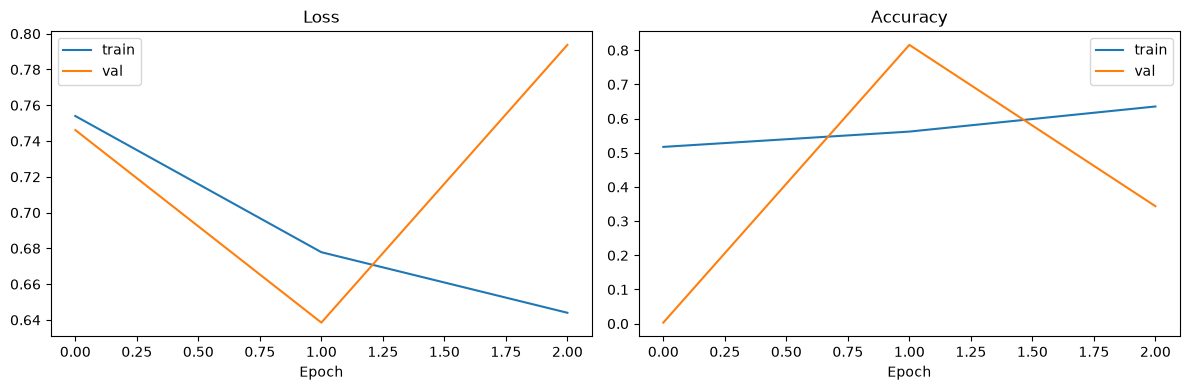

In [18]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Plot Loss
ax1.plot(history_quick.history["loss"], label="train")
ax1.plot(history_quick.history["val_loss"], label="val")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.legend()

# Plot Accuracy
ax2.plot(history_quick.history["accuracy"], label="train")
ax2.plot(history_quick.history["val_accuracy"], label="val")
ax2.set_title("Accuracy")
ax2.set_xlabel("Epoch")
ax2.legend()

plt.tight_layout()
plt.show()